In [2]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import plotly
import optuna.visualization.matplotlib as vis
from IPython.display import display


from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

# Configuración de semillas y dispositivo (GPU/CPU)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

# Descarga de recursos de NLTK
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

# Carga del dataset
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))
class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)

c:\Users\matia\OneDrive\Desktop\RedesNeuronales2026\RedesNeuronales2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Usando dispositivo: cpu


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']


# Funciones de Preprocesamiento, Vectorización y Modelo

In [3]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()

# 1. Función de Preprocesamiento (TODO 1 Resuelto)
def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]

    return " ".join(tokens)

# 2. Función de Vectorización (TODO 2 Resuelto)
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

# 3. Modelo de Regresión Softmax (TODO 3 Resuelto)
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        # Una única capa lineal sin capas ocultas
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        # Devolvemos los logits crudos (CrossEntropyLoss aplica Softmax por dentro)
        return self.linear(x)

# Lógica de Entrenamiento y Carga de Cache

In [4]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)

def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="softmax"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
    return history

print("Precalculando preprocesamiento para las 6 combinaciones (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)

Precalculando preprocesamiento para las 6 combinaciones (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


# Búsqueda de Hiperparámetros

In [5]:
def objective(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-3, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )

    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    model = SoftmaxRegression(input_dim=X_tr.shape[1], num_classes=NUM_CLASSES)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = train_softmax_model(model, train_loader, val_loader, optimizer, epochs=5, run_name=f"trial_{trial.number}")

    return history["val_acc"][-1]

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10) # 10 trials para no demorar tanto

print("Mejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", study.best_value)

[I 2026-10-14 23:07:02,459] A new study created in memory with name: no-name-e1a93e93-6ffb-4586-9268-14dd496daa85


[I 2026-10-14 23:07:16,672] Trial 0 finished with value: 0.5912505523641184 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1_2gram', 'max_features': 2000, 'min_df': 2, 'lr': 0.004380911008209633, 'batch_size': 32}. Best is trial 0 with value: 0.5912505523641184.
[I 2026-10-14 23:07:25,656] Trial 1 finished with value: 0.5850640742377375 and parameters: {'remove_stopwords': False, 'normalization': 'none', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 1, 'lr': 0.0013372542823326173, 'batch_size': 64}. Best is trial 0 with value: 0.5912505523641184.
[I 2026-10-14 23:07:31,465] Trial 2 finished with value: 0.6438356164383562 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 1, 'lr': 0.0018433183893196573, 'batch_size': 32}. Best is trial 2 with value: 0.6438356164383562.
[I 2026-10-14 23:07:40,811] Trial 3 finished with value: 0.7189571365444101 and parameters: 

Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.005330746718628669, 'batch_size': 128}
Mejor accuracy de validación: 0.7326557666813964


# Entrenamiento Final y Métricas

In [6]:
best = study.best_params
BEST_REMOVE_SW = best["remove_stopwords"]
BEST_NORM = best["normalization"]
BEST_NGRAM = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES = best["max_features"]
BEST_MIN_DF = best["min_df"]
BEST_LR = best["lr"]
BEST_BATCH_SIZE = best["batch_size"]
EPOCHS_FINAL = 15

train_texts_final, test_texts_final = preprocessed_cache[(BEST_REMOVE_SW, BEST_NORM)]
X_train_final, X_test_final, vectorizer_final = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF
)

train_loader_final = DataLoader(to_tensor_dataset(X_train_final, newsgroups_train.target), batch_size=BEST_BATCH_SIZE, shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target), batch_size=BEST_BATCH_SIZE, shuffle=False)

model = SoftmaxRegression(input_dim=X_train_final.shape[1], num_classes=NUM_CLASSES)
optimizer = optim.Adam(model.parameters(), lr=BEST_LR)

print("--- Entrenando modelo final ---")
train_softmax_model(model, train_loader_final, test_loader_final, optimizer, epochs=EPOCHS_FINAL, run_name="final")

# Evaluación
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

print(f"\nAccuracy en test final: {accuracy_score(all_labels, all_preds):.4f}\n")

--- Entrenando modelo final ---

Accuracy en test final: 0.6763



# Análisis MLP

## 1. Modelo MLP y optimizadores

In [7]:
import time
from functools import lru_cache

ACTIVATIONS = {
    "relu": nn.ReLU,
    "leaky_relu": nn.LeakyReLU,
    "tanh": nn.Tanh,
    "gelu": nn.GELU,
    "elu": nn.ELU,
}

class MLP(nn.Module):
    def __init__(self, input_dim, num_classes, hidden_units, activation="relu", dropout=0.0):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_units:
            layers += [nn.Linear(prev, h), ACTIVATIONS[activation]()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))  # logits crudos
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def build_optimizer(name, params, lr, weight_decay=0.0,
                    beta1=0.9, beta2=0.999,          # Adam: momentos de orden 1 y 2
                    alpha=0.99, momentum=0.0,        # RMSprop (alpha ~ momento de orden 2)
                    nesterov=False):                 # SGD
    if name == "adam":
        return optim.Adam(params, lr=lr, betas=(beta1, beta2), weight_decay=weight_decay)
    if name == "rmsprop":
        return optim.RMSprop(params, lr=lr, alpha=alpha, momentum=momentum, weight_decay=weight_decay)
    if name == "sgd":
        return optim.SGD(params, lr=lr, momentum=momentum,
                         nesterov=nesterov and momentum > 0, weight_decay=weight_decay)
    raise ValueError(name)

## 2. Entrenamiento con pruning y tiempos

In [8]:
def train_mlp(model, train_loader, val_loader, optimizer, epochs, trial=None):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        run_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
            total += xb.size(0)
        tr_loss, tr_acc = run_loss / total, correct / total

        model.eval()
        run_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                run_loss += criterion(logits, yb).item() * xb.size(0)
                correct += (logits.argmax(1) == yb).sum().item()
                total += xb.size(0)
        v_loss, v_acc = run_loss / total, correct / total

        for k, v in zip(history, [tr_loss, v_loss, tr_acc, v_acc, time.time() - t0]):
            history[k].append(v)

        if trial is not None:
            if np.isnan(tr_loss):                      # entrenamiento divergió
                raise optuna.TrialPruned()
            trial.report(v_acc, epoch)                 # <- pruning
            if trial.should_prune():
                raise optuna.TrialPruned()
    return history

## 3. Objective y estudio de Optuna

In [9]:
# Cachea el split + TF-IDF (matrices sparse, livianas) para no recalcular en cada trial
@lru_cache(maxsize=4)
def get_split_features(remove_sw, norm, ngram, max_features, min_df):
    train_texts, _ = preprocessed_cache[(remove_sw, norm)]
    tr_texts, val_texts, y_tr, y_val = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2,
        random_state=SEED, stratify=newsgroups_train.target)
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram, max_features, min_df)
    return X_tr, X_val, y_tr, y_val

EPOCHS_SEARCH = 15

def objective_mlp(trial):
    # --- NLP (del TP anterior) ---
    remove_sw = trial.suggest_categorical("remove_stopwords", [False, True])
    norm = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram = (1, 1) if trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"]) == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # --- Arquitectura ---
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden = [trial.suggest_categorical(f"units_l{i}", [64, 128, 256, 512]) for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", list(ACTIVATIONS))
    dropout = trial.suggest_float("dropout", 0.0, 0.5)

    # --- Optimizador ---
    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
    lr = trial.suggest_float("lr", 1e-5, 1e-1, log=True)
    wd = trial.suggest_float("weight_decay", 1e-8, 1e-2, log=True)
    opt_kwargs = {}
    if opt_name == "adam":
        opt_kwargs["beta1"] = trial.suggest_float("beta1", 0.8, 0.99)
        opt_kwargs["beta2"] = trial.suggest_float("beta2", 0.9, 0.9999)
    elif opt_name == "rmsprop":
        opt_kwargs["alpha"] = trial.suggest_float("alpha", 0.9, 0.999)
        opt_kwargs["momentum"] = trial.suggest_float("rms_momentum", 0.0, 0.9)
    else:  # sgd
        opt_kwargs["momentum"] = trial.suggest_float("sgd_momentum", 0.0, 0.99)
        opt_kwargs["nesterov"] = trial.suggest_categorical("nesterov", [False, True])

    # --- Datos / modelo ---
    X_tr, X_val, y_tr, y_val = get_split_features(remove_sw, norm, ngram, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=batch_size, shuffle=False)

    model = MLP(X_tr.shape[1], NUM_CLASSES, hidden, activation, dropout)
    optimizer = build_optimizer(opt_name, model.parameters(), lr, wd, **opt_kwargs)

    t0 = time.time()
    history = train_mlp(model, train_loader, val_loader, optimizer, EPOCHS_SEARCH, trial=trial)

    # Guardamos info extra para el análisis posterior
    trial.set_user_attr("train_time", time.time() - t0)
    trial.set_user_attr("n_params", sum(p.numel() for p in model.parameters()))
    trial.set_user_attr("final_train_acc", history["train_acc"][-1])
    trial.set_user_attr("final_val_loss", history["val_loss"][-1])
    return history["val_acc"][-1]


study_mlp = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3),
    study_name="mlp_20newsgroups",
    storage="sqlite:///mlp_study.db",   # si se corta Colab no perdés los trials
    load_if_exists=True,
)
study_mlp.optimize(objective_mlp, n_trials=60)

print("Mejores hiperparámetros:", study_mlp.best_params)
print("Mejor val acc:", study_mlp.best_value)

[I 2026-10-14 23:08:42,792] A new study created in RDB with name: mlp_20newsgroups
[I 2026-10-14 23:09:54,921] Trial 0 finished with value: 0.5143614670790986 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'batch_size': 32, 'n_layers': 1, 'units_l0': 512, 'activation': 'elu', 'dropout': 0.09983689107917987, 'optimizer': 'rmsprop', 'lr': 0.0026926469100861782, 'weight_decay': 1.0547383621352015e-07, 'alpha': 0.9064401077055427, 'rms_momentum': 0.8539969835279999}. Best is trial 0 with value: 0.5143614670790986.
[I 2026-10-14 23:10:58,054] Trial 1 finished with value: 0.25497127706584183 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'batch_size': 64, 'n_layers': 3, 'units_l0': 128, 'units_l1': 64, 'units_l2': 512, 'activation': 'elu', 'dropout': 0.03727532183988541, 'optimizer': 'adam', 'lr': 1.0521761868451132e-05, 'weigh

Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1, 'batch_size': 128, 'n_layers': 1, 'units_l0': 128, 'activation': 'elu', 'dropout': 0.27739876718306417, 'optimizer': 'rmsprop', 'lr': 0.00047485315213308506, 'weight_decay': 5.037299219515546e-08, 'alpha': 0.9498695345251146, 'rms_momentum': 0.39078954979756736}
Mejor val acc: 0.7375165709235528


### 3.b. Estudios controlados, uno por optimizador

In [ ]:
FIXED = dict(remove_sw=True, norm="none", ngram=(1, 1), max_features=10000, min_df=1, batch_size=128)

def make_objective(opt_name):
    def obj(trial):
        n_layers = trial.suggest_int("n_layers", 1, 3)
        hidden = [trial.suggest_categorical(f"units_l{i}", [64, 128, 256, 512]) for i in range(n_layers)]
        activation = trial.suggest_categorical("activation", list(ACTIVATIONS))
        dropout = trial.suggest_float("dropout", 0.0, 0.5)
        wd = trial.suggest_float("weight_decay", 1e-8, 1e-3, log=True)

        if opt_name == "adam":
            lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
            kw = dict(beta1=trial.suggest_float("beta1", 0.8, 0.99),
                      beta2=trial.suggest_float("beta2", 0.9, 0.9999))
        elif opt_name == "rmsprop":
            lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
            kw = dict(alpha=trial.suggest_float("alpha", 0.9, 0.999),
                      momentum=trial.suggest_float("rms_momentum", 0.0, 0.9))
        else:  # sgd
            lr = trial.suggest_float("lr", 1e-2, 2.0, log=True)
            kw = dict(momentum=trial.suggest_float("sgd_momentum", 0.0, 0.99),
                      nesterov=trial.suggest_categorical("nesterov", [False, True]))

        X_tr, X_val, y_tr, y_val = get_split_features(
            FIXED["remove_sw"], FIXED["norm"], FIXED["ngram"], FIXED["max_features"], FIXED["min_df"])
        train_loader = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=FIXED["batch_size"], shuffle=True)
        val_loader = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=FIXED["batch_size"])

        model = MLP(X_tr.shape[1], NUM_CLASSES, hidden, activation, dropout)
        optimizer = build_optimizer(opt_name, model.parameters(), lr, wd, **kw)

        t0 = time.time()
        h = train_mlp(model, train_loader, val_loader, optimizer, EPOCHS_SEARCH, trial=trial)
        trial.set_user_attr("train_time", time.time() - t0)
        trial.set_user_attr("n_params", sum(p.numel() for p in model.parameters()))
        trial.set_user_attr("final_train_acc", h["train_acc"][-1])
        trial.set_user_attr("final_val_loss", h["val_loss"][-1])
        return h["val_acc"][-1]
    return obj

studies = {}
for name in ["adam", "rmsprop", "sgd"]:
    studies[name] = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3),
        study_name=f"mlp_{name}", storage="sqlite:///mlp_study.db", load_if_exists=True)
    studies[name].optimize(make_objective(name), n_trials=20)
    print(name, studies[name].best_value, studies[name].best_params)

[I 2026-10-15 13:21:07,917] A new study created in RDB with name: mlp_adam
[I 2026-10-15 13:21:39,898] Trial 0 finished with value: 0.7079098541758727 and parameters: {'n_layers': 2, 'units_l0': 64, 'units_l1': 256, 'activation': 'tanh', 'dropout': 0.09091248360355031, 'weight_decay': 8.260808399079588e-08, 'lr': 0.0004059611610484307, 'beta1': 0.8997037220101252, 'beta2': 0.9431513073623474}. Best is trial 0 with value: 0.7079098541758727.
[I 2026-10-15 13:22:07,843] Trial 1 finished with value: 0.7074679628811312 and parameters: {'n_layers': 1, 'units_l0': 64, 'activation': 'leaky_relu', 'dropout': 0.023225206359998862, 'weight_decay': 1.0907475835157686e-05, 'lr': 0.00021930485556643703, 'beta1': 0.8123598026672032, 'beta2': 0.994793665171608}. Best is trial 0 with value: 0.7079098541758727.
[I 2026-10-15 13:22:41,403] Trial 2 finished with value: 0.4617764030048608 and parameters: {'n_layers': 3, 'units_l0': 64, 'units_l1': 256, 'units_l2': 64, 'activation': 'gelu', 'dropout': 0.46

adam 0.7264692885550155 {'n_layers': 1, 'units_l0': 64, 'activation': 'leaky_relu', 'dropout': 0.12114856961161177, 'weight_decay': 8.536626306560013e-08, 'lr': 0.0016991491283578077, 'beta1': 0.9325626386966769, 'beta2': 0.9975166294733993}


[I 2026-10-15 13:30:41,884] A new study created in RDB with name: mlp_rmsprop
[I 2026-10-15 13:31:12,762] Trial 0 finished with value: 0.6950950066283694 and parameters: {'n_layers': 2, 'units_l0': 64, 'units_l1': 256, 'activation': 'tanh', 'dropout': 0.09091248360355031, 'weight_decay': 8.260808399079588e-08, 'lr': 0.0004059611610484307, 'alpha': 0.9519508867315916, 'rms_momentum': 0.3887505167779042}. Best is trial 0 with value: 0.6950950066283694.
[I 2026-10-15 13:31:39,683] Trial 1 finished with value: 0.7189571365444101 and parameters: {'n_layers': 1, 'units_l0': 64, 'activation': 'leaky_relu', 'dropout': 0.023225206359998862, 'weight_decay': 1.0907475835157686e-05, 'lr': 0.00021930485556643703, 'alpha': 0.9064401077055427, 'rms_momentum': 0.8539969835279999}. Best is trial 1 with value: 0.7189571365444101.
[I 2026-10-15 13:32:12,301] Trial 2 finished with value: 0.4962439239946973 and parameters: {'n_layers': 3, 'units_l0': 64, 'units_l1': 256, 'units_l2': 64, 'activation': 'gelu

rmsprop 0.7308882015024304 {'n_layers': 1, 'units_l0': 64, 'activation': 'gelu', 'dropout': 0.1654490124263246, 'weight_decay': 2.0786996906897747e-08, 'lr': 0.0004187594718900631, 'alpha': 0.932193148880648, 'rms_momentum': 0.6566455605042577}


[I 2026-10-15 13:39:34,765] A new study created in RDB with name: mlp_sgd
[I 2026-10-15 13:39:59,273] Trial 0 finished with value: 0.31374281926646047 and parameters: {'n_layers': 2, 'units_l0': 64, 'units_l1': 256, 'activation': 'tanh', 'dropout': 0.09091248360355031, 'weight_decay': 8.260808399079588e-08, 'lr': 0.05012686302434878, 'sgd_momentum': 0.5195088673159155, 'nesterov': False}. Best is trial 0 with value: 0.31374281926646047.
[I 2026-10-15 13:41:30,461] Trial 1 finished with value: 0.1780821917808219 and parameters: {'n_layers': 2, 'units_l0': 512, 'units_l1': 64, 'activation': 'elu', 'dropout': 0.4828160165372797, 'weight_decay': 0.00011015056790269616, 'lr': 0.05022563311994769, 'sgd_momentum': 0.09669539286632003, 'nesterov': False}. Best is trial 0 with value: 0.31374281926646047.
[I 2026-10-15 13:42:33,220] Trial 2 finished with value: 0.052585064074237735 and parameters: {'n_layers': 1, 'units_l0': 256, 'activation': 'relu', 'dropout': 0.4847923138822793, 'weight_decay

## 4. Entrenamiento final del mejor trial

In [11]:
SOFTMAX_TEST_ACC = accuracy_score(all_labels, all_preds)
SOFTMAX_BEST_VAL = study.best_value
print(f"Softmax - test acc: {SOFTMAX_TEST_ACC:.4f} | mejor val acc: {SOFTMAX_BEST_VAL:.4f}")

Softmax - test acc: 0.6763 | mejor val acc: 0.7327


MLP     - test acc: 0.6823 | tiempo: 47.8s
Softmax - test acc: 0.6763
                          precision    recall  f1-score   support

             alt.atheism       0.50      0.48      0.49       319
           comp.graphics       0.62      0.66      0.64       389
 comp.os.ms-windows.misc       0.63      0.61      0.62       394
comp.sys.ibm.pc.hardware       0.62      0.65      0.63       392
   comp.sys.mac.hardware       0.74      0.68      0.71       385
          comp.windows.x       0.80      0.68      0.74       395
            misc.forsale       0.74      0.77      0.76       390
               rec.autos       0.48      0.74      0.58       396
         rec.motorcycles       0.77      0.72      0.75       398
      rec.sport.baseball       0.86      0.80      0.83       397
        rec.sport.hockey       0.90      0.88      0.89       399
               sci.crypt       0.82      0.72      0.76       396
         sci.electronics       0.61      0.58      0.59       393
     

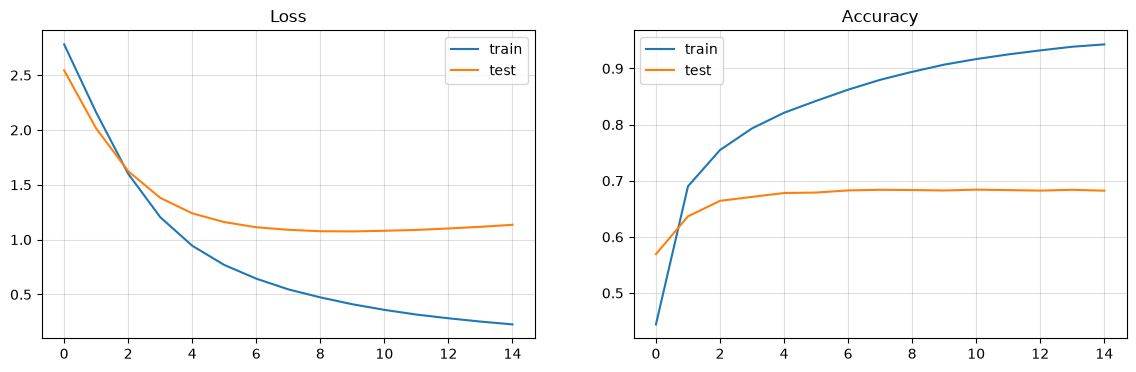

In [12]:
def model_and_opt_from_params(p, input_dim):
    hidden = [p[f"units_l{i}"] for i in range(p["n_layers"])]
    model = MLP(input_dim, NUM_CLASSES, hidden, p["activation"], p["dropout"])
    if p["optimizer"] == "adam":
        kw = dict(beta1=p["beta1"], beta2=p["beta2"])
    elif p["optimizer"] == "rmsprop":
        kw = dict(alpha=p["alpha"], momentum=p["rms_momentum"])
    else:
        kw = dict(momentum=p["sgd_momentum"], nesterov=p["nesterov"])
    opt = build_optimizer(p["optimizer"], model.parameters(), p["lr"], p["weight_decay"], **kw)
    return model, opt

best = study_mlp.best_params
ngram = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
train_texts, test_texts = preprocessed_cache[(best["remove_stopwords"], best["normalization"])]
X_train, X_test, _ = vectorize_data(train_texts, test_texts, ngram, best["max_features"], best["min_df"])

train_loader = DataLoader(to_tensor_dataset(X_train, newsgroups_train.target),
                          batch_size=best["batch_size"], shuffle=True)
test_loader = DataLoader(to_tensor_dataset(X_test, newsgroups_test.target),
                         batch_size=best["batch_size"], shuffle=False)

torch.manual_seed(SEED)
model_final, opt_final = model_and_opt_from_params(best, X_train.shape[1])

t0 = time.time()
hist_final = train_mlp(model_final, train_loader, test_loader, opt_final, epochs=15)
t_final = time.time() - t0

model_final.eval()
preds, labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        preds.extend(model_final(xb.to(device)).argmax(1).cpu().numpy())
        labels.extend(yb.numpy())

MLP_TEST_ACC = accuracy_score(labels, preds)
print(f"MLP     - test acc: {MLP_TEST_ACC:.4f} | tiempo: {t_final:.1f}s")
print(f"Softmax - test acc: {SOFTMAX_TEST_ACC:.4f}")
print(classification_report(labels, preds, target_names=class_names))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
a1.plot(hist_final["train_loss"], label="train"); a1.plot(hist_final["val_loss"], label="test")
a1.set_title("Loss"); a1.legend(); a1.grid(alpha=.4)
a2.plot(hist_final["train_acc"], label="train"); a2.plot(hist_final["val_acc"], label="test")
a2.set_title("Accuracy"); a2.legend(); a2.grid(alpha=.4)
plt.show()

## 5.Experimento de overfitting

1x64     params=   641,364 train_acc=0.973 val_acc=0.721 best_val_loss_epoch=14 tiempo=34s
1x512    params= 5,130,772 train_acc=0.972 val_acc=0.719 best_val_loss_epoch=5 tiempo=171s
2x512    params= 5,393,428 train_acc=0.973 val_acc=0.680 best_val_loss_epoch=2 tiempo=173s
3x1024   params=12,360,724 train_acc=0.973 val_acc=0.637 best_val_loss_epoch=2 tiempo=409s
3x2048   params=28,915,732 train_acc=0.973 val_acc=0.652 best_val_loss_epoch=2 tiempo=909s


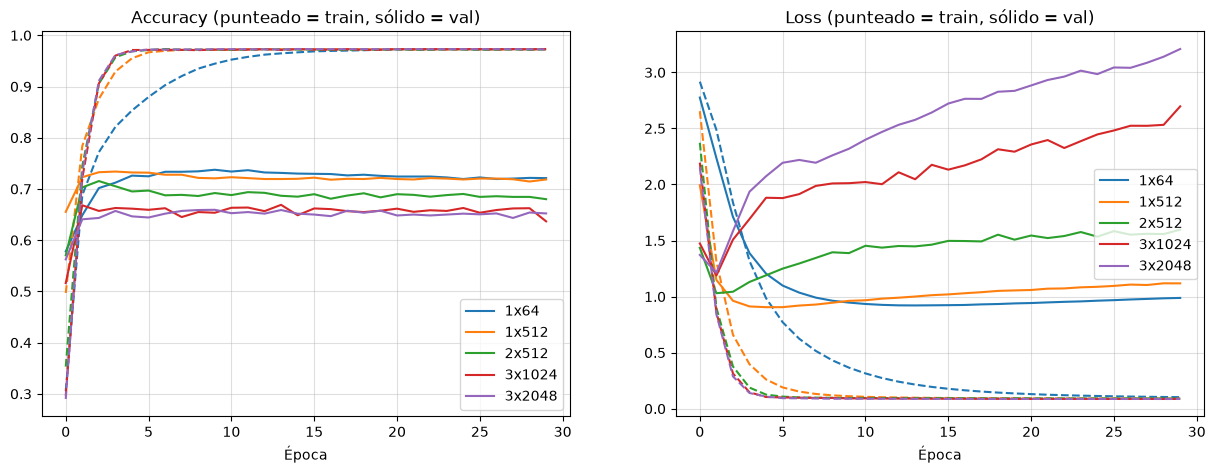

In [13]:
# Datos: mismo preprocesamiento del mejor trial, split train/val
X_tr, X_val, y_tr, y_val = get_split_features(
    best["remove_stopwords"], best["normalization"], ngram, best["max_features"], best["min_df"])
of_train = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=128, shuffle=True)
of_val = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=128)

OVERFIT_CONFIGS = {
    "1x64":           [64],
    "1x512":          [512],
    "2x512":          [512, 512],
    "3x1024":         [1024, 1024, 1024],
    "3x2048":         [2048, 2048, 2048],
}
EPOCHS_OF = 30
of_results = {}

for name, hidden in OVERFIT_CONFIGS.items():
    torch.manual_seed(SEED)
    m = MLP(X_tr.shape[1], NUM_CLASSES, hidden, activation="relu", dropout=0.0)
    o = build_optimizer("adam", m.parameters(), lr=1e-3, weight_decay=0.0)
    t0 = time.time()
    h = train_mlp(m, of_train, of_val, o, EPOCHS_OF)
    of_results[name] = dict(hist=h, time=time.time() - t0,
                            n_params=sum(p.numel() for p in m.parameters()))
    print(f"{name:8s} params={of_results[name]['n_params']:>10,d} "
          f"train_acc={h['train_acc'][-1]:.3f} val_acc={h['val_acc'][-1]:.3f} "
          f"best_val_loss_epoch={int(np.argmin(h['val_loss']))+1} "
          f"tiempo={of_results[name]['time']:.0f}s")

# Curvas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, r in of_results.items():
    l, = axes[0].plot(r["hist"]["train_acc"], linestyle="--")
    axes[0].plot(r["hist"]["val_acc"], color=l.get_color(), label=name)
    l, = axes[1].plot(r["hist"]["train_loss"], linestyle="--")
    axes[1].plot(r["hist"]["val_loss"], color=l.get_color(), label=name)
axes[0].set_title("Accuracy (punteado = train, sólido = val)")
axes[1].set_title("Loss (punteado = train, sólido = val)")
for a in axes: a.set_xlabel("Época"); a.legend(); a.grid(alpha=.4)
plt.show()

In [14]:
from collections import Counter, defaultdict

X = X_tr.tocsr(); X.sort_indices()
groups = defaultdict(list)
for i in range(X.shape[0]):
    s, e = X.indptr[i], X.indptr[i + 1]
    key = (X.indices[s:e].tobytes(), X.data[s:e].round(6).tobytes())
    groups[key].append(y_tr[i])

# Mínimo de errores inevitables: en cada grupo de vectores idénticos solo se puede acertar la etiqueta mayoritaria
unfit = sum(len(v) - Counter(v).most_common(1)[0][1] for v in groups.values())
vacios = sum(len(v) for k, v in groups.items() if len(k[0]) == 0)
print(f"Docs con vector vacío: {vacios} | errores inevitables >= {unfit} "
      f"-> techo de train acc <= {1 - unfit / X.shape[0]:.3f}")

Docs con vector vacío: 262 | errores inevitables >= 241 -> techo de train acc <= 0.973


## 6. Análisis de todos los trials

C:\Users\matia\AppData\Local\Temp\ipykernel_25412\3209506538.py:25: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  display(vis.plot_param_importances(study_mlp))
c:\Users\matia\OneDrive\Desktop\RedesNeuronales2026\RedesNeuronales2026\.venv\Lib\site-packages\optuna\importance\_ped_anova\evaluator.py:353: UserWarning: Some regimes for parameter `sgd_momentum` have less than 2 trials. The importance of the parameter may be inaccurate.
  optuna_warn(
c:\Users\matia\OneDrive\Desktop\RedesNeuronales2026\RedesNeuronales2026\.venv\Lib\site-packages\optuna\importance\_ped_anova\evaluator.py:353: UserWarning: Some regimes for parameter `nesterov` have less than 2 trials. The importance of the parameter may be inaccurate.
  optuna_warn(


<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

C:\Users\matia\AppData\Local\Temp\ipykernel_25412\3209506538.py:26: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  display(vis.plot_optimization_history(study_mlp))


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>


=== Por optimizer ===
           n_trials  pct_podados  n_completos  val_media  val_max  \
optimizer                                                           
adam             40        0.525           19      0.669    0.737   
rmsprop          14        0.214           11      0.671    0.738   
sgd               6        0.833            1      0.053    0.053   

           dur_media_s  gap_medio  
optimizer                          
adam            53.446      0.246  
rmsprop         42.493      0.264  
sgd             48.461     -0.004  

=== Por activation ===
            n_trials  pct_podados  n_completos  val_media  val_max  \
activation                                                           
elu               45        0.489           23      0.666    0.738   
gelu               4        0.500            2      0.321    0.590   
leaky_relu         5        0.400            3      0.722    0.733   
relu               2        0.500            1      0.719    0.719   
tanh   

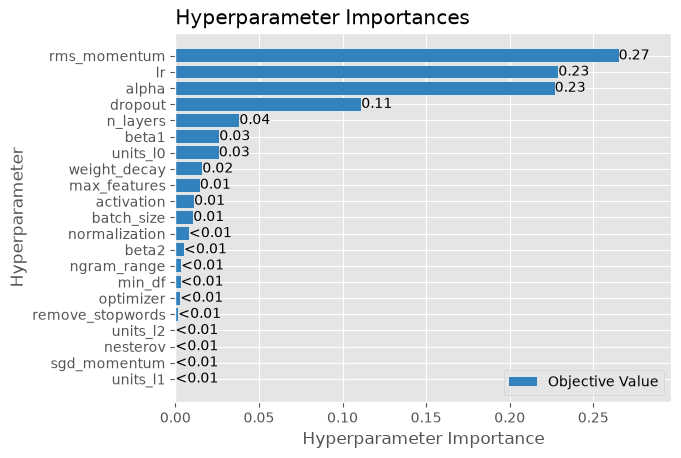

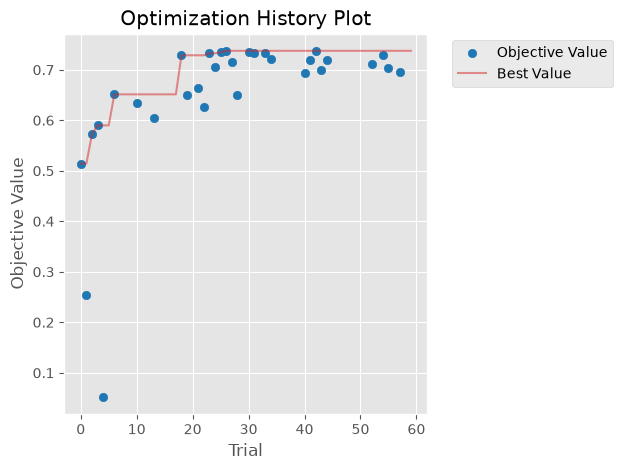

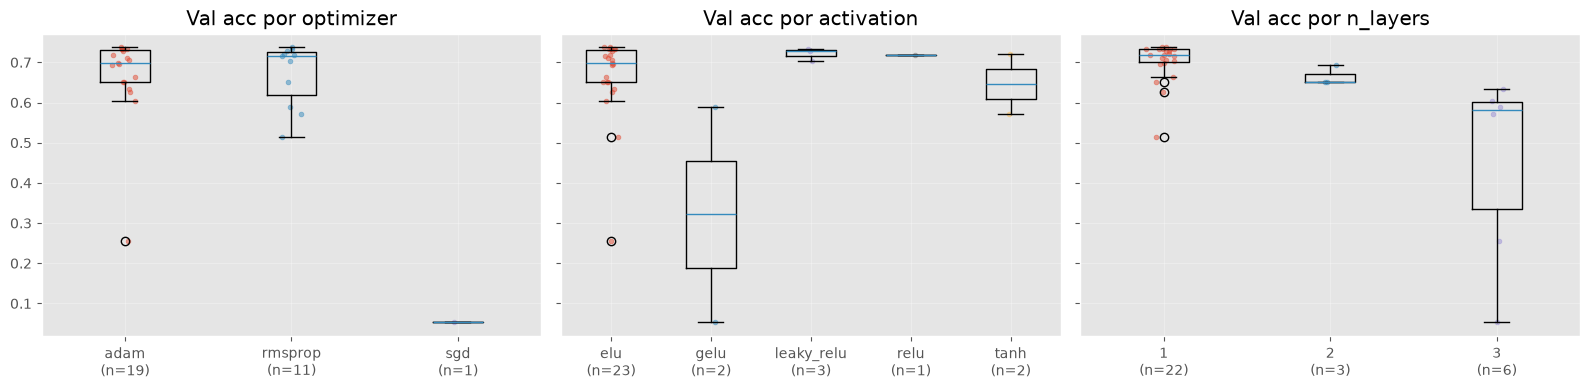

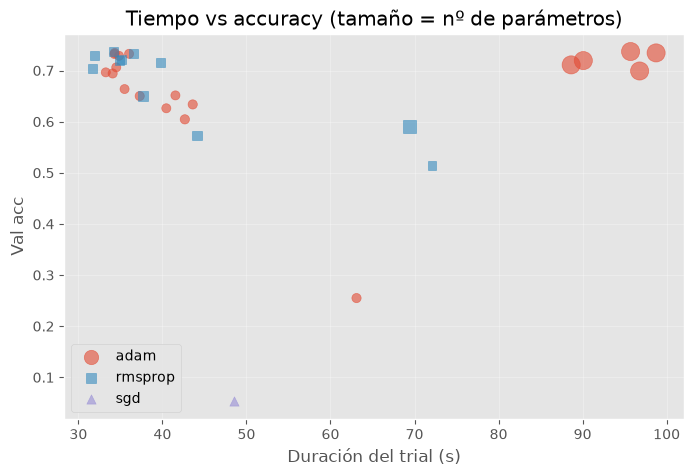

Completos: 31 | tiempo total 25.5 min
Podados:   29 | tiempo total 6.4 min
Sin pruning (estimación gruesa, cada trial = mediana de completos): 37.7 min
          count  mean  std   min   25%   50%   75%   max
state                                                   
COMPLETE   31.0  15.0  0.0  15.0  15.0  15.0  15.0  15.0
PRUNED     29.0   4.0  0.0   4.0   4.0   4.0   4.0   4.0
            params  train_acc  val_acc    gap  val_loss_min  epoca_min  \
1x64      641364.0      0.973    0.721  0.252         0.921       14.0   
1x512    5130772.0      0.972    0.719  0.254         0.906        5.0   
2x512    5393428.0      0.973    0.680  0.293         1.030        2.0   
3x1024  12360724.0      0.973    0.637  0.336         1.188        2.0   
3x2048  28915732.0      0.973    0.652  0.320         1.214        2.0   

        val_loss_final  tiempo_s  
1x64             0.988    34.143  
1x512            1.118   170.723  
2x512            1.597   173.307  
3x1024           2.697   408.888  


In [15]:
import pandas as pd

def study_to_df(st):
    rows = []
    for t in st.trials:
        ivs = t.intermediate_values
        rows.append(dict(
            number=t.number, state=t.state.name, val_acc=t.value,
            last_val_acc=ivs[max(ivs)] if ivs else np.nan,
            epochs_run=len(ivs),
            dur=t.duration.total_seconds() if t.duration else np.nan,
            n_params=t.user_attrs.get("n_params"),
            train_acc=t.user_attrs.get("final_train_acc"),
            **{k: t.params.get(k) for k in
               ["optimizer", "activation", "n_layers", "lr", "dropout",
                "weight_decay", "max_features", "ngram_range", "batch_size"]}))
    return pd.DataFrame(rows)

df = study_to_df(study_mlp)
done = df[df.state == "COMPLETE"].copy()
pruned = df[df.state == "PRUNED"]
done["gap"] = done.train_acc - done.val_acc

# --- 1. Importancia de HPs e historia de optimización ---
display(vis.plot_param_importances(study_mlp))
display(vis.plot_optimization_history(study_mlp))

# --- 2. Tablas por optimizador / activación / profundidad ---
for col in ["optimizer", "activation", "n_layers"]:
    a = df.groupby(col).agg(n_trials=("state", "size"),
                            pct_podados=("state", lambda s: (s == "PRUNED").mean()))
    b = done.groupby(col).agg(n_completos=("val_acc", "size"), val_media=("val_acc", "mean"),
                              val_max=("val_acc", "max"), dur_media_s=("dur", "mean"),
                              gap_medio=("gap", "mean"))
    print(f"\n=== Por {col} ===")
    print(a.join(b).round(3))

# --- 3. Boxplots (con n visible) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, ["optimizer", "activation", "n_layers"]):
    gs = sorted(done[col].unique())
    data = [done[done[col] == g].val_acc.values for g in gs]
    ax.boxplot(data)
    for i, d in enumerate(data, 1):
        ax.scatter(np.random.normal(i, 0.04, len(d)), d, alpha=.5, s=12)
    ax.set_xticks(range(1, len(gs) + 1))
    ax.set_xticklabels([f"{g}\n(n={len(d)})" for g, d in zip(gs, data)])
    ax.set_title(f"Val acc por {col}"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# --- 4. Tiempo vs accuracy ---
plt.figure(figsize=(8, 5))
for opt, mk in {"adam": "o", "rmsprop": "s", "sgd": "^"}.items():
    d = done[done.optimizer == opt]
    plt.scatter(d.dur, d.val_acc, marker=mk, s=d.n_params / 30000, alpha=.6, label=opt)
plt.xlabel("Duración del trial (s)"); plt.ylabel("Val acc")
plt.title("Tiempo vs accuracy (tamaño = nº de parámetros)")
plt.legend(); plt.grid(alpha=.3); plt.show()

# --- 5. Efecto del pruning ---
med = done.dur.median()
print(f"Completos: {len(done)} | tiempo total {done.dur.sum()/60:.1f} min")
print(f"Podados:   {len(pruned)} | tiempo total {pruned.dur.sum()/60:.1f} min")
print(f"Sin pruning (estimación gruesa, cada trial = mediana de completos): "
      f"{len(df) * med / 60:.1f} min")
print(df.groupby("state").epochs_run.describe().round(1))

# --- 6. Resumen del experimento de overfitting ---
of_df = pd.DataFrame({n: dict(
    params=r["n_params"], train_acc=r["hist"]["train_acc"][-1], val_acc=r["hist"]["val_acc"][-1],
    gap=r["hist"]["train_acc"][-1] - r["hist"]["val_acc"][-1],
    val_loss_min=min(r["hist"]["val_loss"]), epoca_min=int(np.argmin(r["hist"]["val_loss"])) + 1,
    val_loss_final=r["hist"]["val_loss"][-1], tiempo_s=r["time"])
    for n, r in of_results.items()}).T
print(of_df.round(3))

### 6.b. Análisis de optimizadores

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
STORAGE = "sqlite:///mlp_study.db"

studies = {name: optuna.load_study(study_name=f"mlp_{name}", storage=STORAGE)
           for name in ["adam", "rmsprop", "sgd"]}
study_mlp = optuna.load_study(study_name="mlp_20newsgroups", storage=STORAGE)

def study_to_df(st):
    rows = []
    for t in st.trials:
        ivs = t.intermediate_values
        rows.append(dict(
            number=t.number, state=t.state.name, val_acc=t.value,
            last_val_acc=ivs[max(ivs)] if ivs else np.nan,
            epochs_run=len(ivs),
            dur=t.duration.total_seconds() if t.duration else np.nan,
            n_params=t.user_attrs.get("n_params"),
            train_acc=t.user_attrs.get("final_train_acc"),
            **{k: t.params.get(k) for k in
               ["optimizer", "activation", "n_layers", "lr", "dropout",
                "weight_decay", "max_features", "ngram_range", "batch_size"]}))
    return pd.DataFrame(rows)

for n, st in studies.items():
    print(n, "->", len(st.trials), "trials")

c:\Users\matia\OneDrive\Desktop\RedesNeuronales2026\RedesNeuronales2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


adam -> 20 trials
rmsprop -> 20 trials
sgd -> 14 trials


optimizador  trials  completos  podados  val_max  val_mediana  dur_completos_s  dur_podados_s
       adam      20         11        9   0.7265       0.7123          37.3480        18.0074
    rmsprop      20          9       11   0.7309       0.7172          44.4673        11.9577
        sgd      14          8        5   0.7008       0.4744          64.4618        19.2633


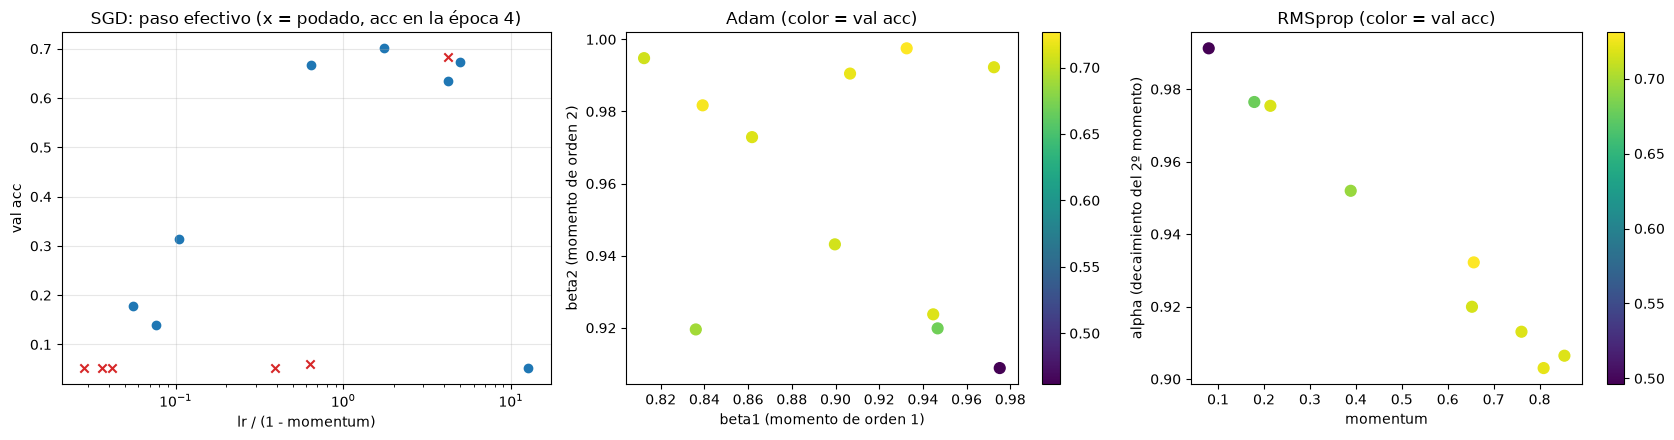

In [3]:
# --- Resumen por optimizador ---
rows = []
for name, st in studies.items():
    d = study_to_df(st)
    dd, pp = d[d.state == "COMPLETE"], d[d.state == "PRUNED"]
    rows.append(dict(optimizador=name, trials=len(d), completos=len(dd), podados=len(pp),
                     val_max=dd.val_acc.max(), val_mediana=dd.val_acc.median(),
                     dur_completos_s=dd.dur.mean(), dur_podados_s=pp.dur.mean()))
print(pd.DataFrame(rows).round(4).to_string(index=False))

# --- Hiperparámetros propios de cada optimizador ---
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# SGD: paso efectivo lr/(1-momentum)
for t in studies["sgd"].trials:
    if "sgd_momentum" not in t.params:
        continue
    eff = t.params["lr"] / (1 - t.params["sgd_momentum"])
    if t.state.name == "COMPLETE":
        ax[0].scatter(eff, t.value, c="C0")
    elif t.intermediate_values:   # podado: accuracy en la última época medida
        ax[0].scatter(eff, t.intermediate_values[max(t.intermediate_values)], marker="x", c="C3")
ax[0].set_xscale("log"); ax[0].set_xlabel("lr / (1 - momentum)"); ax[0].set_ylabel("val acc")
ax[0].set_title("SGD: paso efectivo (x = podado, acc en la época 4)"); ax[0].grid(alpha=.3)

# Adam: momentos de orden 1 y 2
ts = [t for t in studies["adam"].trials if t.state.name == "COMPLETE"]
sc = ax[1].scatter([t.params["beta1"] for t in ts], [t.params["beta2"] for t in ts],
                   c=[t.value for t in ts], cmap="viridis", s=60)
ax[1].set_xlabel("beta1 (momento de orden 1)"); ax[1].set_ylabel("beta2 (momento de orden 2)")
ax[1].set_title("Adam (color = val acc)"); plt.colorbar(sc, ax=ax[1])

# RMSprop: alpha (orden 2) y momentum (orden 1)
ts = [t for t in studies["rmsprop"].trials if t.state.name == "COMPLETE"]
sc = ax[2].scatter([t.params["rms_momentum"] for t in ts], [t.params["alpha"] for t in ts],
                   c=[t.value for t in ts], cmap="viridis", s=60)
ax[2].set_xlabel("momentum"); ax[2].set_ylabel("alpha (decaimiento del 2º momento)")
ax[2].set_title("RMSprop (color = val acc)"); plt.colorbar(sc, ax=ax[2])
plt.tight_layout(); plt.show()

## 7. Correciones y Validación

relu       1 capas seed=0 val=0.7335 48s
relu       1 capas seed=1 val=0.7384 35s
relu       1 capas seed=2 val=0.7357 34s
relu       2 capas seed=0 val=0.7004 35s
relu       2 capas seed=1 val=0.6973 37s
relu       2 capas seed=2 val=0.6885 35s
relu       3 capas seed=0 val=0.6151 40s
relu       3 capas seed=1 val=0.6509 40s
relu       3 capas seed=2 val=0.6217 39s
leaky_relu 1 capas seed=0 val=0.7349 34s
leaky_relu 1 capas seed=1 val=0.7384 35s
leaky_relu 1 capas seed=2 val=0.7362 37s
leaky_relu 2 capas seed=0 val=0.7057 39s
leaky_relu 2 capas seed=1 val=0.6986 33s
leaky_relu 2 capas seed=2 val=0.6938 36s
leaky_relu 3 capas seed=0 val=0.6262 40s
leaky_relu 3 capas seed=1 val=0.6483 38s
leaky_relu 3 capas seed=2 val=0.6293 39s
tanh       1 capas seed=0 val=0.7327 42s
tanh       1 capas seed=1 val=0.7406 36s
tanh       1 capas seed=2 val=0.7366 38s
tanh       2 capas seed=0 val=0.7084 36s
tanh       2 capas seed=1 val=0.7053 36s
tanh       2 capas seed=2 val=0.6951 36s
tanh       3 cap

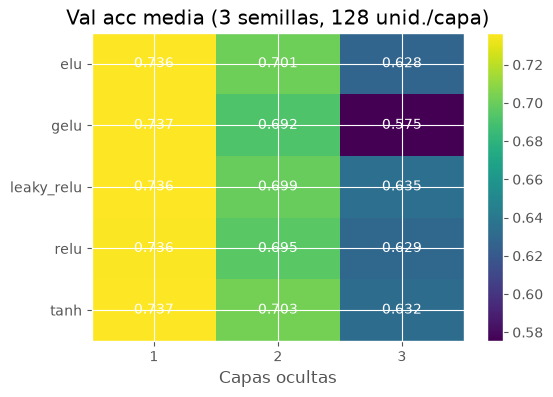

In [17]:
import itertools

SEEDS = [0, 1, 2]
X_tr, X_val, y_tr, y_val = get_split_features(True, "none", (1, 1), 10000, 1)
g_train = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=128, shuffle=True)
g_val = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=128)

rows = []
for act, nl, seed in itertools.product(ACTIVATIONS, [1, 2, 3], SEEDS):
    torch.manual_seed(seed)
    m = MLP(X_tr.shape[1], NUM_CLASSES, [128] * nl, act, dropout=0.28)
    o = build_optimizer("adam", m.parameters(), lr=5e-4, weight_decay=1e-7)
    t0 = time.time()
    h = train_mlp(m, g_train, g_val, o, epochs=15)
    rows.append(dict(activation=act, n_layers=nl, seed=seed, val_acc=h["val_acc"][-1],
                     train_acc=h["train_acc"][-1], time=time.time() - t0))
    print(f"{act:10s} {nl} capas seed={seed} val={rows[-1]['val_acc']:.4f} {rows[-1]['time']:.0f}s")

grid = pd.DataFrame(rows)
summ = grid.groupby(["activation", "n_layers"]).agg(
    val_mean=("val_acc", "mean"), val_std=("val_acc", "std"),
    gap=("train_acc", "mean"), time_s=("time", "mean")).round(4)
print(summ)

# Heatmap de accuracy media
piv = grid.pivot_table(index="activation", columns="n_layers", values="val_acc", aggfunc="mean")
plt.figure(figsize=(6, 4))
plt.imshow(piv.values, cmap="viridis", aspect="auto")
plt.xticks(range(3), piv.columns); plt.yticks(range(len(piv)), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        plt.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", color="w")
plt.xlabel("Capas ocultas"); plt.title("Val acc media (3 semillas, 128 unid./capa)")
plt.colorbar(); plt.show()

## 8. Comparación contra softmax con varias semillas

In [18]:
def make_loaders(p):
    ng = (1, 1) if p["ngram_range"] == "1gram" else (1, 2)
    tr, te = preprocessed_cache[(p["remove_stopwords"], p["normalization"])]
    Xtr, Xte, _ = vectorize_data(tr, te, ng, p["max_features"], p["min_df"])
    return (DataLoader(to_tensor_dataset(Xtr, newsgroups_train.target), batch_size=p["batch_size"], shuffle=True),
            DataLoader(to_tensor_dataset(Xte, newsgroups_test.target), batch_size=p["batch_size"]),
            Xtr.shape[1])

def eval_acc(model, loader):
    model.eval(); c = n = 0
    with torch.no_grad():
        for xb, yb in loader:
            c += (model(xb.to(device)).argmax(1).cpu() == yb).sum().item(); n += len(yb)
    return c / n

N_SEEDS = 5
cmp_rows = []
for name, p in [("softmax", study.best_params), ("mlp", study_mlp.best_params)]:
    trl, tel, d = make_loaders(p)
    for seed in range(N_SEEDS):
        torch.manual_seed(seed)
        if name == "softmax":
            m = SoftmaxRegression(d, NUM_CLASSES); o = optim.Adam(m.parameters(), lr=p["lr"])
        else:
            m, o = model_and_opt_from_params(p, d)
        t0 = time.time()
        train_mlp(m, trl, tel, o, epochs=15)       # sirve para cualquier nn.Module
        t = time.time() - t0
        acc = eval_acc(m, tel)
        cmp_rows.append(dict(modelo=name, seed=seed, test_acc=acc, tiempo_s=t,
                             params=sum(q.numel() for q in m.parameters())))
        print(f"{name:8s} seed={seed} test_acc={acc:.4f} {t:.0f}s")

cmp = pd.DataFrame(cmp_rows)
print(cmp.groupby("modelo").agg(acc_media=("test_acc", "mean"), acc_std=("test_acc", "std"),
                                tiempo_medio_s=("tiempo_s", "mean"), params=("params", "first")).round(4))

softmax  seed=0 test_acc=0.6764 25s
softmax  seed=1 test_acc=0.6746 31s
softmax  seed=2 test_acc=0.6766 27s
softmax  seed=3 test_acc=0.6767 20s
softmax  seed=4 test_acc=0.6758 20s
mlp      seed=0 test_acc=0.6843 56s
mlp      seed=1 test_acc=0.6815 58s
mlp      seed=2 test_acc=0.6802 56s
mlp      seed=3 test_acc=0.6841 58s
mlp      seed=4 test_acc=0.6807 55s
         acc_media  acc_std  tiempo_medio_s   params
modelo                                              
mlp         0.6822   0.0019         56.6739  1282708
softmax     0.6760   0.0009         24.6264   200020
